# Credit Card Customer Segmentation: Unsupervised Clustering
### Algorithms: K-Means Clustering & Agglomerative Hierarchical Clustering
**Dataset:** [Credit Card Dataset for Clustering (Kaggle / Arjun Bhasin)](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata)  
---

## 1. Executive Summary & Business Formulation

Customer segmentation is an essential unsupervised learning strategy in consumer banking and credit card portfolio management. By grouping customers based on their transactional patterns, credit utilization, payment habits, and cash advance behavior, financial institutions can:
- **Tailor Marketing Campaigns:** Deliver personalized promotional offers (e.g., zero-interest balance transfers, retail cashback rewards, installment loans).
- **Manage Credit Risk:** Flag customers exhibiting high cash advance usage combined with minimal payments as potential credit risks.
- **Optimize Product Design:** Structure revolving credit tiers and rewards according to empirical customer behavior personas.

In this notebook, we implement and rigorously compare two primary unsupervised clustering paradigms:
1. **Partitional Clustering:** **K-Means Clustering** (centroid-based, optimizing within-cluster sum of squares).
2. **Hierarchical Clustering:** **Agglomerative Hierarchical Clustering** (bottom-up dendrogram-based with Ward's minimum variance linkage).


In [20]:
# Core scientific & ML libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-Learn tools
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

# Scipy hierarchical clustering
import scipy.cluster.hierarchy as sch


---
## 2. Dataset Ingestion

The dataset consists of 8,950 active credit card holders evaluated over an active 6-month observation window across 18 behavioral attributes:
* `CUST_ID`: Unique customer account identifier
* `BALANCE`: Monthly balance amount left in account
* `BALANCE_FREQUENCY`: How frequently balance is updated ($0 = \text{not frequent}, 1 = \text{frequent}$)
* `PURCHASES`: Total monetary amount of purchases made
* `ONEOFF_PURCHASES`: Maximum purchase amount done in one-go
* `INSTALLMENTS_PURCHASES`: Amount of purchases done in installments
* `CASH_ADVANCE`: Cash in advance given by the user
* `PURCHASES_FREQUENCY`: Frequency of purchases made ($0 \to 1$)
* `ONEOFF_PURCHASES_FREQUENCY`: Frequency of one-off purchases ($0 \to 1$)
* `PURCHASES_INSTALLMENTS_FREQUENCY`: Frequency of installment purchases ($0 \to 1$)
* `CASH_ADVANCE_FREQUENCY`: Frequency of cash advances taken ($0 \to 1$)
* `CASH_ADVANCE_TRX`: Number of cash advance transactions
* `PURCHASES_TRX`: Number of purchase transactions
* `CREDIT_LIMIT`: Credit card transaction limit for the user
* `PAYMENTS`: Amount of payment done by user
* `MINIMUM_PAYMENTS`: Minimum amount of payment made by user
* `PRC_FULL_PAYMENT`: Percent of full payment paid by user ($0 \to 1$)
* `TENURE`: Tenure of credit card service for user (months)


In [21]:
import os

# Robust path handling: check primary and fallback locations
data_paths = [
    os.path.join("..", "clustering_dataset", "CC GENERAL.csv"),
    os.path.join("..", "data", "clustering", "CC GENERAL.csv"),
    os.path.join("clustering_dataset", "CC GENERAL.csv"),
    os.path.join("data", "clustering", "CC GENERAL.csv")
]

data_file = None
for path in data_paths:
    if os.path.exists(path):
        data_file = path
        break

if data_file is None:
    raise FileNotFoundError("CC GENERAL.csv not found. Please run data/clustering/get_dataset.py first.")

df_raw = pd.read_csv(data_file)
print(f"Loaded dataset from: {data_file}")
print(f"Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()

Loaded dataset from: ..\clustering_dataset\CC GENERAL.csv
Dataset Dimensions: 8950 rows, 18 columns


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [22]:
# Audit Data types and Missing Values
audit_df = pd.DataFrame({
    'Data Type': df_raw.dtypes,
    'Null Count': df_raw.isnull().sum(),
    'Null %': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'Unique Values': df_raw.nunique()
})
audit_df

,Data Type,Null Count,Null %,Unique Values
CUST_ID,str,0,0.00,8950
BALANCE,float64,0,0.00,8871
BALANCE_FREQUENCY,float64,0,0.00,43
PURCHASES,float64,0,0.00,6203
ONEOFF_PURCHASES,float64,0,0.00,4014
INSTALLMENTS_PURCHASES,float64,0,0.00,4452
CASH_ADVANCE,float64,0,0.00,4323
PURCHASES_FREQUENCY,float64,0,0.00,47
ONEOFF_PURCHASES_FREQUENCY,float64,0,0.00,47
PURCHASES_INSTALLMENTS_FREQUENCY,float64,0,0.00,47


In [23]:
# Statistical Summary of Behavioral Features
df_raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.47,2081.53,0.00,128.28,873.39,2054.14,19043.14
BALANCE_FREQUENCY,8950.0,0.88,0.24,0.00,0.89,1.00,1.00,1.00
PURCHASES,8950.0,1003.20,2136.63,0.00,39.64,361.28,1110.13,49039.57
ONEOFF_PURCHASES,8950.0,592.44,1659.89,0.00,0.00,38.00,577.40,40761.25
INSTALLMENTS_PURCHASES,8950.0,411.07,904.34,0.00,0.00,89.00,468.64,22500.00
CASH_ADVANCE,8950.0,978.87,2097.16,0.00,0.00,0.00,1113.82,47137.21
PURCHASES_FREQUENCY,8950.0,0.49,0.40,0.00,0.08,0.50,0.92,1.00
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.20,0.30,0.00,0.00,0.08,0.30,1.00
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.36,0.40,0.00,0.00,0.17,0.75,1.00
CASH_ADVANCE_FREQUENCY,8950.0,0.14,0.20,0.00,0.00,0.00,0.22,1.50


---
## 3. Exploratory Data Analysis (EDA)

Key observations from the initial statistical audit:
1. **Severe Positive Skewness:** Most financial expenditure variables (`BALANCE`, `PURCHASES`, `CASH_ADVANCE`, `PAYMENTS`, `MINIMUM_PAYMENTS`) exhibit large differences between mean and median, accompanied by long right tails.
2. **Missing Values:** `MINIMUM_PAYMENTS` has 313 missing values (~3.5%), and `CREDIT_LIMIT` has 1 missing value.
3. **Identifier Leakage:** `CUST_ID` is an arbitrary categorical string that must be removed prior to computing Euclidean distances.


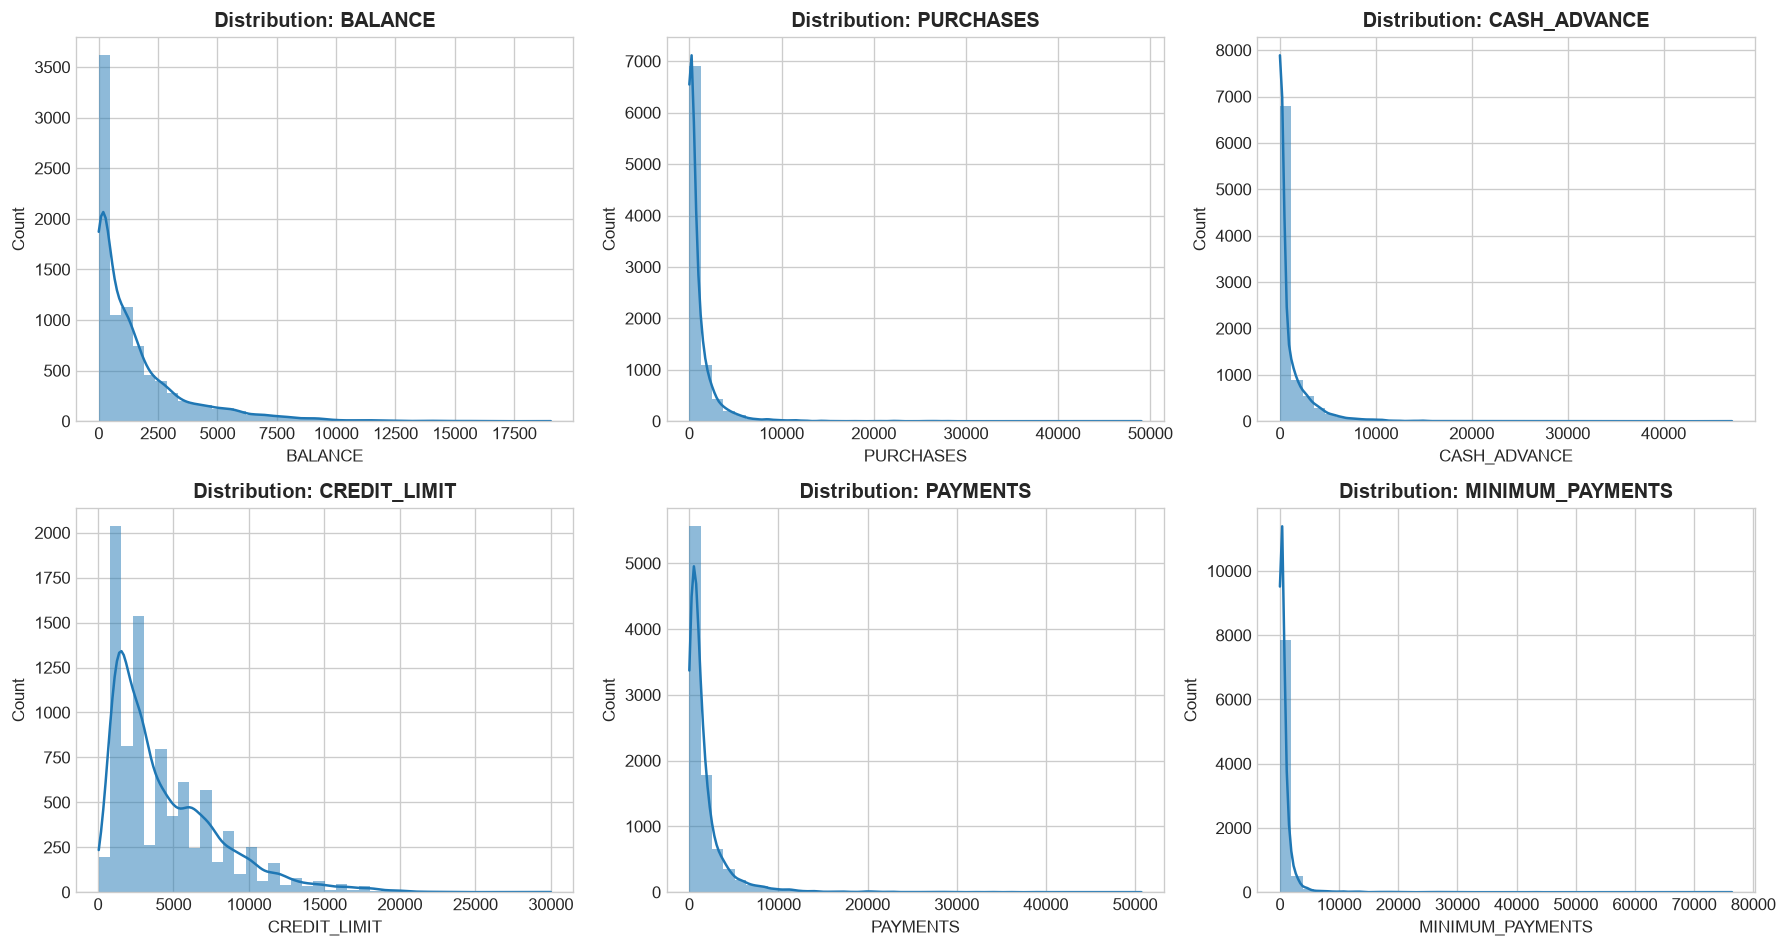

In [24]:
# Visualize distributions of key financial attributes
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
key_features = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS']

for i, col in enumerate(key_features):
    ax = axes[i // 3, i % 3]
    sns.histplot(df_raw[col].dropna(), kde=True, bins=40, ax=ax, color='#1f77b4', edgecolor='none')
    ax.set_title(f'Distribution: {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

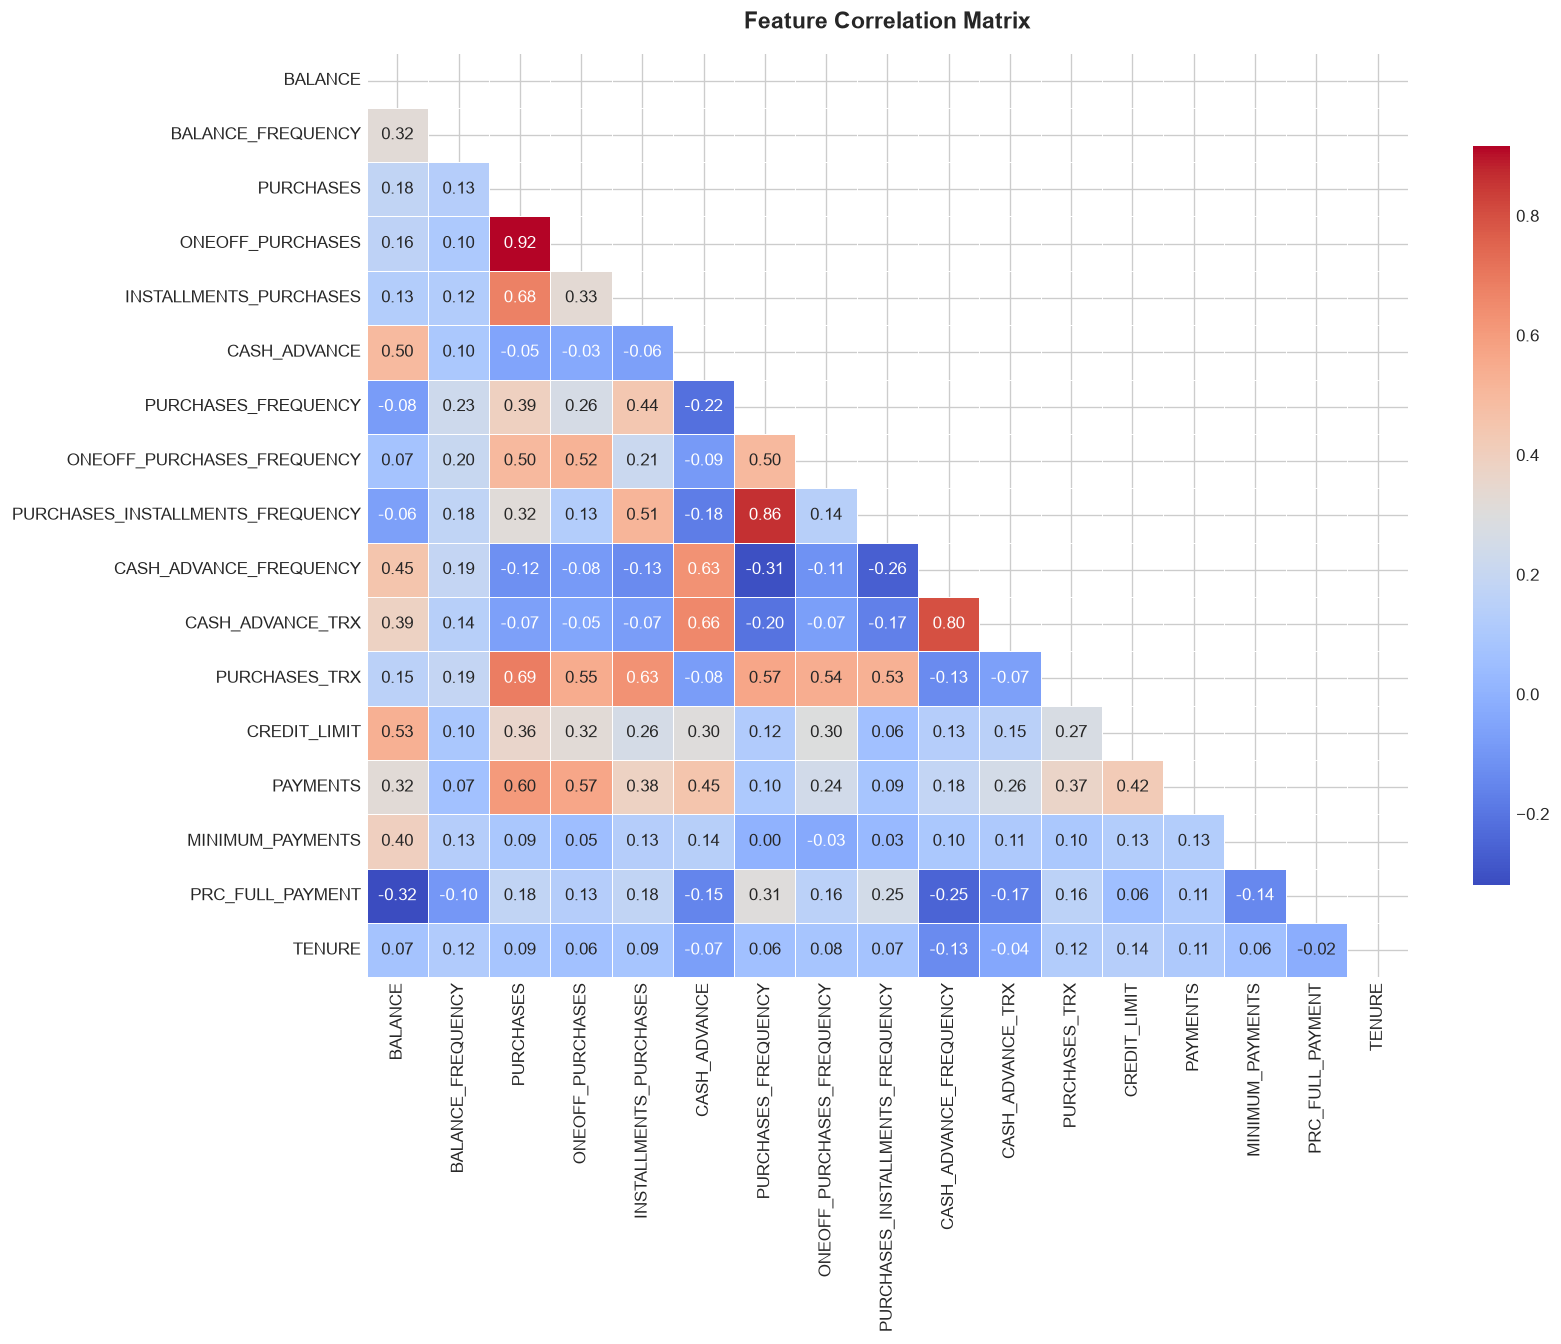

In [25]:
# Correlation Matrix of Numerical Features
plt.figure(figsize=(14, 10))
corr = df_raw.drop(columns=['CUST_ID']).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', annot=True, fmt='.2f', linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=15)
plt.show()

---
## 4. Data Preprocessing & Feature Engineering

Distance-based clustering algorithms such as K-Means and Agglomerative Clustering measure similarity via Euclidean distance:
$$d(x_i, x_j) = \sqrt{\sum_{d=1}^{D} (x_{id} - x_{jd})^2}$$

Because Euclidean distance is sensitive to scale and variance, unscaled or highly skewed features with wide dynamic ranges (e.g. `CREDIT_LIMIT` ranging up to $30,000) will dominate features measured on a bounded $0 \to 1$ scale (such as `PURCHASES_FREQUENCY`).

Therefore, our preprocessing pipeline consists of:
1. **Drop `CUST_ID`**: Identifier column.
2. **Missing Value Imputation**: Imputing `MINIMUM_PAYMENTS` and `CREDIT_LIMIT` using median imputation to resist outlier distortion.
3. **Log-Transformation (`log1p`)**: Applying $y = \ln(1 + x)$ to heavily skewed financial features to stabilize variance and normalize heavy tails.
4. **Standardization (`StandardScaler`)**: Scaling features to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$).


In [26]:
# 1. Separate Customer ID and target dataframe
customer_ids = df_raw['CUST_ID']
df_clean = df_raw.drop(columns=['CUST_ID']).copy()

# 2. Impute missing values with column median
df_clean['CREDIT_LIMIT'] = df_clean['CREDIT_LIMIT'].fillna(df_clean['CREDIT_LIMIT'].median())
df_clean['MINIMUM_PAYMENTS'] = df_clean['MINIMUM_PAYMENTS'].fillna(df_clean['MINIMUM_PAYMENTS'].median())

print(f"Total remaining missing values: {df_clean.isnull().sum().sum()}")

# 3. Log-Transformation on skewed financial metrics
skewed_cols = [
    'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
    'CASH_ADVANCE', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT',
    'PAYMENTS', 'MINIMUM_PAYMENTS'
]

df_transformed = df_clean.copy()
for col in skewed_cols:
    df_transformed[col] = np.log1p(np.maximum(0, df_transformed[col]))

# 4. Standard Scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_transformed)

print(f"Scaled feature matrix shape: {X_scaled.shape}")
print(f"Mean across features: {np.mean(X_scaled, axis=0).round(4)}")
print(f"Standard deviation across features: {np.std(X_scaled, axis=0).round(4)}")

Total remaining missing values: 0
Scaled feature matrix shape: (8950, 17)
Mean across features: [ 0.  0.  0.  0.  0.  0. -0. -0.  0.  0. -0.  0. -0.  0. -0.  0.  0.]
Standard deviation across features: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


---
## 5. Dimensionality Reduction: Principal Component Analysis (PCA)

Principal Component Analysis (PCA) projects the 17-dimensional standardized behavioral space onto orthogonal principal axes with maximal variance:
$$X_{\text{PCA}} = X W$$
where $W$ represents the eigenvector matrix of the covariance matrix $X^T X$.

PCA serves two purposes:
1. Eliminates multicollinearity among transaction indicators.
2. Enables 2D and 3D visual verification of clusters and cluster boundaries.


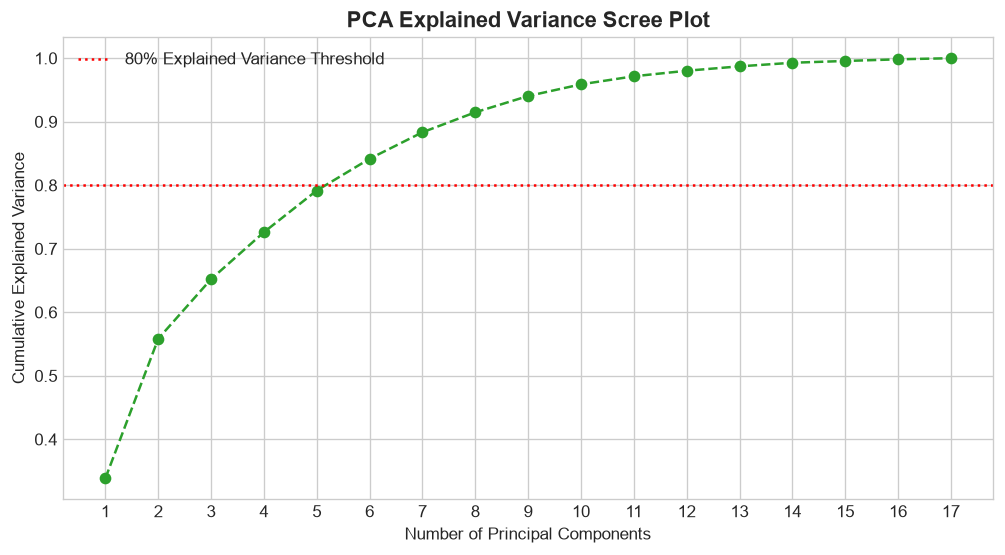

2-Component Explained Variance: PC1 = 33.88%, PC2 = 21.96%
Total variance retained in 2D projection: 55.84%


In [27]:
# Apply PCA across all components to inspect explained variance
pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='--', color='#2ca02c')
plt.axhline(y=0.80, color='r', linestyle=':', label='80% Explained Variance Threshold')
plt.title('PCA Explained Variance Scree Plot', fontsize=13, fontweight='bold')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.xticks(range(1, len(cum_var) + 1))
plt.legend()
plt.show()

# 2-Component PCA for direct 2D projection
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)
print(f"2-Component Explained Variance: PC1 = {pca_2d.explained_variance_ratio_[0]:.2%}, PC2 = {pca_2d.explained_variance_ratio_[1]:.2%}")
print(f"Total variance retained in 2D projection: {np.sum(pca_2d.explained_variance_ratio_):.2%}")

---
## 6. Algorithm 1: K-Means Clustering

### Mathematical Formulation
K-Means partitions $n$ observations into $k$ disjoint clusters $S = \{S_1, S_2, \dots, S_k\}$ by minimizing the within-cluster sum of squares (WCSS / Inertia):
$$J(S) = \sum_{j=1}^{k} \sum_{x_i \in S_j} \| x_i - \mu_j \|^2$$
where $\mu_j = \frac{1}{|S_j|} \sum_{x_i \in S_j} x_i$ is the centroid of cluster $S_j$.

### Finding the Optimal Number of Clusters ($k$)
We employ three complementary quantitative heuristics:
1. **Elbow Method (Inertia):** Identifies the point of diminishing returns where adding an additional cluster does not yield a substantial drop in WCSS.
2. **Silhouette Coefficient:** Measures how well-separated a sample is from neighboring clusters:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}, \quad s(i) \in [-1, 1]$$
   where $a(i)$ is the mean intra-cluster distance and $b(i)$ is the mean nearest-cluster distance.
3. **Davies-Bouldin Index (DBI):** Evaluates cluster similarity as the ratio of within-cluster scatter to between-cluster separation (lower is better).
4. **Calinski-Harabasz Index (Variance Ratio Criterion):** Ratio of between-cluster dispersion to within-cluster dispersion (higher is better).


In [28]:
# Systematic Search for Optimal K in K-Means (K = 2 to 8)
k_values = list(range(2, 9))
wcss_list = []
silhouette_list = []
db_list = []
ch_list = []

for k in k_values:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=42)
    labels = km.fit_predict(X_scaled)
    
    wcss_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, labels, sample_size=3000, random_state=42))
    db_list.append(davies_bouldin_score(X_scaled, labels))
    ch_list.append(calinski_harabasz_score(X_scaled, labels))

# Summary table for K-Means search
k_eval_df = pd.DataFrame({
    'k': k_values,
    'Inertia (WCSS)': [round(x, 1) for x in wcss_list],
    'Silhouette Score (↑)': [round(x, 4) for x in silhouette_list],
    'Davies-Bouldin (↓)': [round(x, 4) for x in db_list],
    'Calinski-Harabasz (↑)': [round(x, 1) for x in ch_list]
})
k_eval_df

,k,Inertia (WCSS),Silhouette Score (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
0,2,113331.6,0.2481,1.5065,3064.9
1,3,95644.7,0.2257,1.6812,2642.9
2,4,86547.0,0.2180,1.6876,2260.4
3,5,77933.1,0.2228,1.6011,2129.6
4,6,71656.4,0.2188,1.4660,2009.4
5,7,67972.6,0.2223,1.4240,1845.8
6,8,64555.5,0.2128,1.4570,1733.3


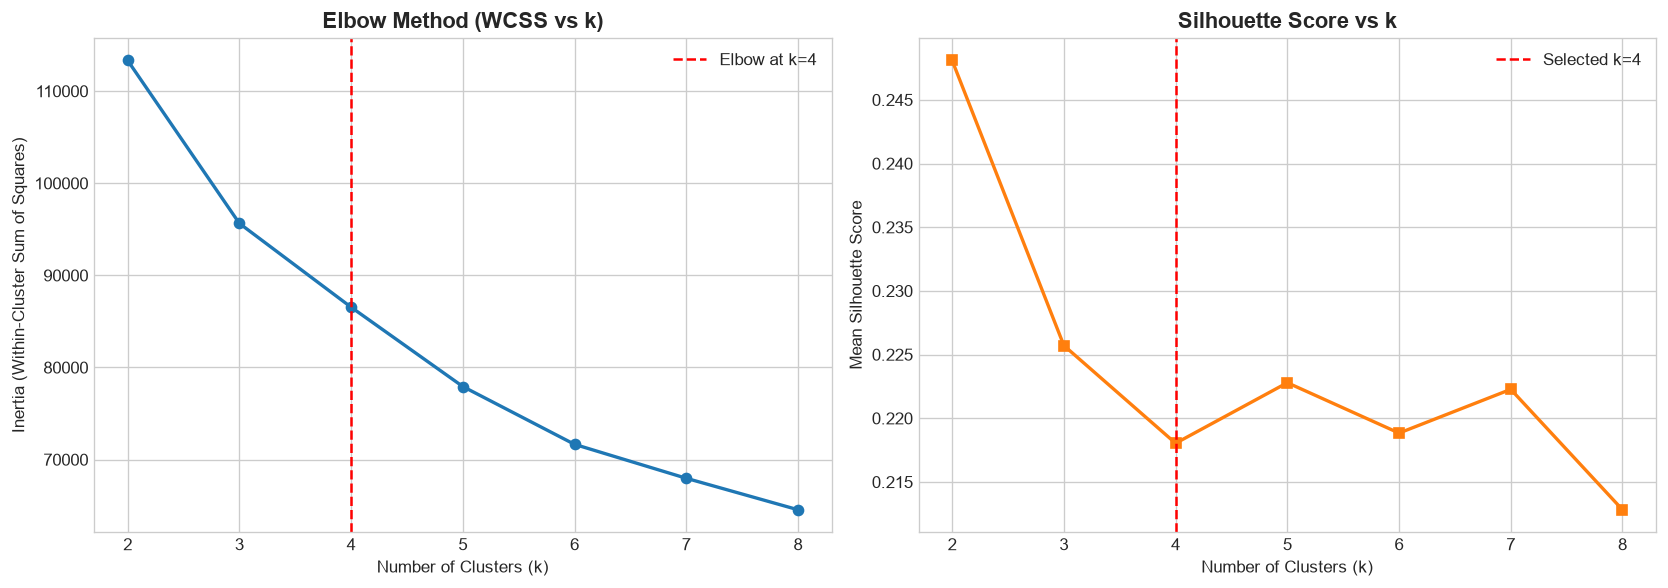

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method Plot
axes[0].plot(k_values, wcss_list, marker='o', linewidth=2, color='#1f77b4')
axes[0].axvline(x=4, color='red', linestyle='--', label='Elbow at k=4')
axes[0].set_title('Elbow Method (WCSS vs k)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].legend()

# Silhouette Score Plot
axes[1].plot(k_values, silhouette_list, marker='s', linewidth=2, color='#ff7f0e')
axes[1].axvline(x=4, color='red', linestyle='--', label='Selected k=4')
axes[1].set_title('Silhouette Score vs k', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Mean Silhouette Score')
axes[1].legend()

plt.tight_layout()
plt.show()

In [30]:
# Final K-Means Model Selection: k=4
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', n_init=20, max_iter=500, random_state=42)
kmeans_labels = kmeans_final.fit_predict(X_scaled)

# Add cluster labels to clean dataframe
df_clean['KMeans_Cluster'] = kmeans_labels

# Compute Cluster Centroids in 2D PCA space
pca_centroids = pca_2d.transform(kmeans_final.cluster_centers_)

# Cluster distribution
print("K-Means Cluster Value Counts:")
print(df_clean['KMeans_Cluster'].value_counts().sort_index())

K-Means Cluster Value Counts:
KMeans_Cluster
0    1570
1    2760
2    2580
3    2040
Name: count, dtype: int64


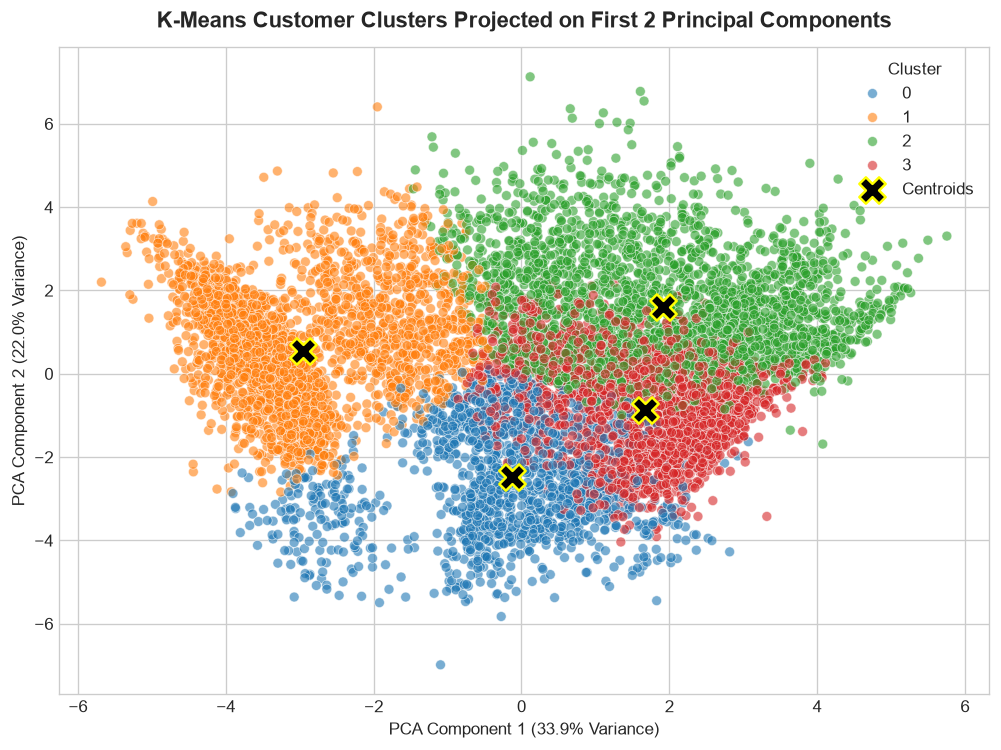

In [31]:
# 2D PCA Visualization of K-Means Clusters
plt.figure(figsize=(10, 7))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels,
    palette=palette,
    alpha=0.6,
    s=35,
    legend='full'
)

# Plot Centroids
plt.scatter(
    pca_centroids[:, 0],
    pca_centroids[:, 1],
    c='black',
    s=250,
    marker='X',
    edgecolor='yellow',
    linewidth=1.5,
    label='Centroids'
)

plt.title('K-Means Customer Clusters Projected on First 2 Principal Components', fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'PCA Component 1 ({pca_2d.explained_variance_ratio_[0]:.1%} Variance)')
plt.ylabel(f'PCA Component 2 ({pca_2d.explained_variance_ratio_[1]:.1%} Variance)')
plt.legend(title='Cluster', loc='upper right')
plt.show()

In [32]:
# Cluster Persona Profiling: Mean Feature Values per Cluster
profile_cols = [
    'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
    'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY',
    'CREDIT_LIMIT', 'PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE'
]

cluster_profile = df_clean.groupby('KMeans_Cluster')[profile_cols].mean()

# Formatting cluster profiling table
print("=== K-Means Cluster Behavioral Summary (Mean Values) ===")
display(cluster_profile.round(2))

=== K-Means Cluster Behavioral Summary (Mean Values) ===


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
KMeans_Cluster,,,,,,,,,,,
0,213.58,351.39,271.26,80.50,113.63,0.25,0.02,3561.17,742.55,0.16,11.33
1,2460.81,103.32,79.46,23.90,2220.06,0.07,0.30,4364.17,1818.29,0.03,11.39
2,2243.73,2604.15,1751.80,852.41,862.92,0.82,0.11,6393.23,2933.03,0.17,11.81
3,532.39,697.61,67.39,631.11,112.15,0.81,0.02,2986.83,862.81,0.29,11.45


### K-Means Behavioral Personas Interpretation
* **Cluster 0 — Conservative / Low-Activity Users:** Low balance, low overall purchases, modest credit limits. These customers use cards infrequently, maintaining low balances.
* **Cluster 1 — Cash Advance / Revolving Borrowers:** Moderate to high balance, very low retail purchases, but exceptionally high `CASH_ADVANCE` and `CASH_ADVANCE_FREQUENCY`. They use cards as emergency loans rather than shopping instruments.
* **Cluster 2 — VIP / High-Volume Spenders:** Highest `BALANCE`, highest `PURCHASES` (both one-off and installments), highest `CREDIT_LIMIT`, and highest `PAYMENTS`. Most lucrative premium demographic.
* **Cluster 3 — Active Retail / Installment Purchasers:** High `PURCHASES_FREQUENCY` and `INSTALLMENTS_PURCHASES` relative to balance, high percentage of full payments. Reliable transactors who purchase frequently and pay on time.


---
## 7. Algorithm 2: Agglomerative Hierarchical Clustering

### Mathematical Formulation
Agglomerative Hierarchical Clustering is a bottom-up clustering strategy. It begins with each point $x_i$ as an individual singleton cluster $\{x_i\}$, and sequentially merges the pair of clusters $(A, B)$ that minimizes a chosen linkage criterion until a single encompassing cluster remains.

#### Ward's Minimum Variance Linkage
We utilize **Ward's Linkage**, which minimizes the total within-cluster variance increase upon merging:
$$\Delta \text{ESS}(A, B) = \frac{n_A n_B}{n_A + n_B} \| \mu_A - \mu_B \|^2$$
where $n_A, n_B$ are cluster cardinalities and $\mu_A, \mu_B$ are cluster centroids. Ward's criterion generates compact, spherical clusters similar in nature to K-Means, making it the ideal comparative benchmark.

### Dendrogram Construction
To avoid $O(N^2)$ memory explosion when plotting a graphical tree for 8,950 observations, we construct the dendrogram using a stratified representative sample ($n=1,500$) with truncated leaf visualization.


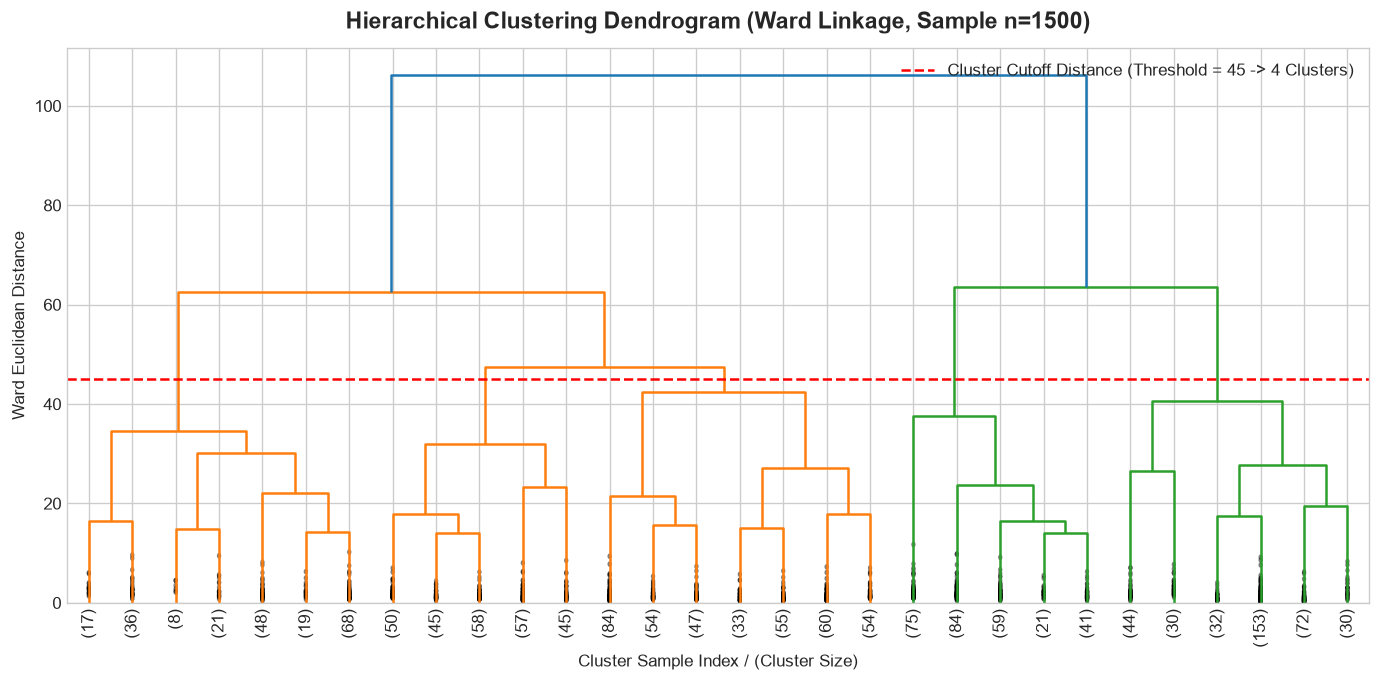

In [33]:
# Construct Hierarchical Linkage Matrix (Ward's Method) on a stratified sample
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), size=1500, replace=False)
X_sample = X_scaled[sample_idx]

linkage_matrix = sch.linkage(X_sample, method='ward', metric='euclidean')

# Plot Dendrogram
plt.figure(figsize=(14, 6))
sch.dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)
plt.axhline(y=45, color='r', linestyle='--', label='Cluster Cutoff Distance (Threshold = 45 -> 4 Clusters)')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage, Sample n=1500)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Cluster Sample Index / (Cluster Size)')
plt.ylabel('Ward Euclidean Distance')
plt.legend()
plt.show()

In [34]:
# Fit Agglomerative Clustering on Full Dataset with k=4
agg_model = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
agg_labels = agg_model.fit_predict(X_scaled)

df_clean['Agglomerative_Cluster'] = agg_labels

print("Agglomerative Cluster Value Counts:")
print(df_clean['Agglomerative_Cluster'].value_counts().sort_index())

Agglomerative Cluster Value Counts:
Agglomerative_Cluster
0    3272
1    2255
2    1856
3    1567
Name: count, dtype: int64


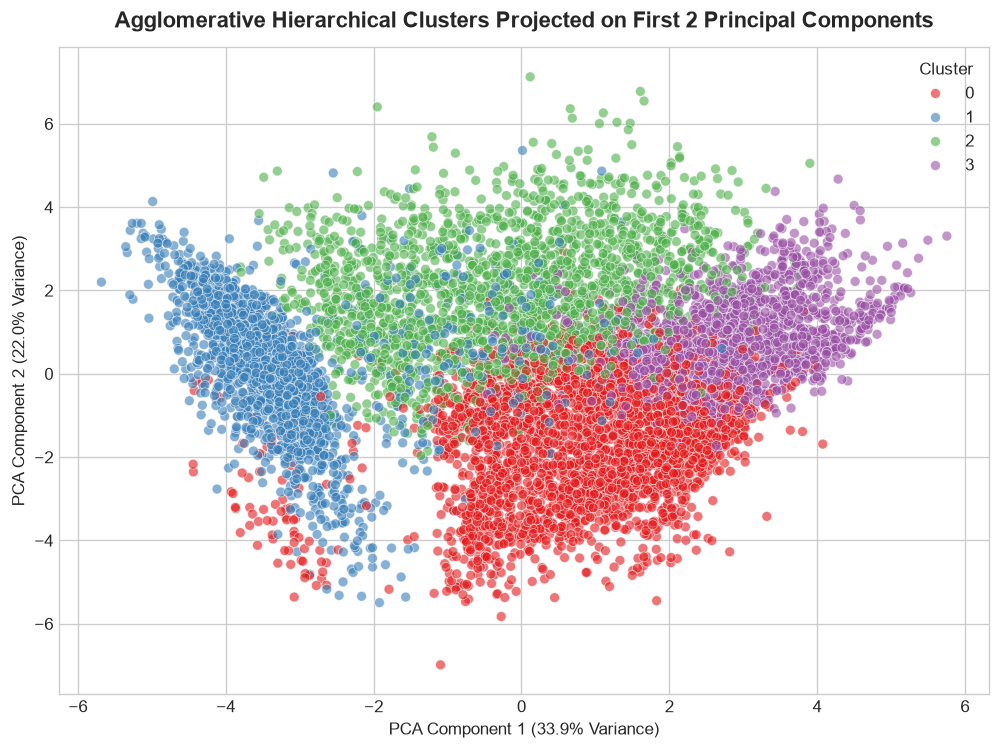

In [35]:
# 2D PCA Visualization of Agglomerative Clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=agg_labels,
    palette='Set1',
    alpha=0.6,
    s=35,
    legend='full'
)

plt.title('Agglomerative Hierarchical Clusters Projected on First 2 Principal Components', fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'PCA Component 1 ({pca_2d.explained_variance_ratio_[0]:.1%} Variance)')
plt.ylabel(f'PCA Component 2 ({pca_2d.explained_variance_ratio_[1]:.1%} Variance)')
plt.legend(title='Cluster', loc='upper right')
plt.show()

---
## 8. Comparative Evaluation: K-Means vs. Agglomerative Hierarchical

We assess both algorithms across multiple quantitative validation metrics:
* **Silhouette Score:** Evaluates cluster cohesion and separation ($s \in [-1, 1]$, higher is better).
* **Davies-Bouldin Index:** Measures average similarity between each cluster and its most similar counterpart (lower is better).
* **Calinski-Harabasz Index:** Ratio of between-cluster dispersion to within-cluster dispersion (higher is better).
* **Adjusted Rand Index (ARI):** Measures the empirical agreement/overlap between K-Means labels and Agglomerative labels, corrected for chance ($ARI=1.0$ indicates identical clustering).


In [36]:
# Compute validation scores on full dataset
km_sil = silhouette_score(X_scaled, kmeans_labels, sample_size=4000, random_state=42)
km_db = davies_bouldin_score(X_scaled, kmeans_labels)
km_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

agg_sil = silhouette_score(X_scaled, agg_labels, sample_size=4000, random_state=42)
agg_db = davies_bouldin_score(X_scaled, agg_labels)
agg_ch = calinski_harabasz_score(X_scaled, agg_labels)

ari_score = adjusted_rand_score(kmeans_labels, agg_labels)

# Build comprehensive comparison dataframe
comparison_df = pd.DataFrame({
    'Metric / Property': [
        'Silhouette Score (Cohesion & Separation ↑)',
        'Davies-Bouldin Index (Lower is Better ↓)',
        'Calinski-Harabasz Index (Higher is Better ↑)',
        'Time Complexity',
        'Space Complexity',
        'Scalability to Large N',
        'Cluster Geometry Assumption'
    ],
    'K-Means (k=4)': [
        f"{km_sil:.4f}",
        f"{km_db:.4f}",
        f"{km_ch:.1f}",
        "O(n * k * d * i) [Linear]",
        "O(n * d) [Low]",
        "Excellent (Easily handles millions)",
        "Convex / Spherical (Voronoi)"
    ],
    'Agglomerative Hierarchical (k=4)': [
        f"{agg_sil:.4f}",
        f"{agg_db:.4f}",
        f"{agg_ch:.1f}",
        "O(n^2 log n) [Polynomial]",
        "O(n^2) [High memory matrix]",
        "Poor (Prohibitive beyond ~20k rows)",
        "Ward minimizes variance; flexible"
    ]
})

print(f"Agreement between K-Means and Agglomerative (Adjusted Rand Index): {ari_score:.4f}")
comparison_df

Agreement between K-Means and Agglomerative (Adjusted Rand Index): 0.3497


,Metric / Property,K-Means (k=4),Agglomerative Hierarchical (k=4)
0,Silhouette Score (Cohesion & Separation ↑),0.2174,0.1673
1,Davies-Bouldin Index (Lower is Better ↓),1.6876,1.7326
2,Calinski-Harabasz Index (Higher is Better ↑),2260.4,1870.1
3,Time Complexity,O(n * k * d * i) [Linear],O(n^2 log n) [Polynomial]
4,Space Complexity,O(n * d) [Low],O(n^2) [High memory matrix]
5,Scalability to Large N,Excellent (Easily handles millions),Poor (Prohibitive beyond ~20k rows)
6,Cluster Geometry Assumption,Convex / Spherical (Voronoi),Ward minimizes variance; flexible


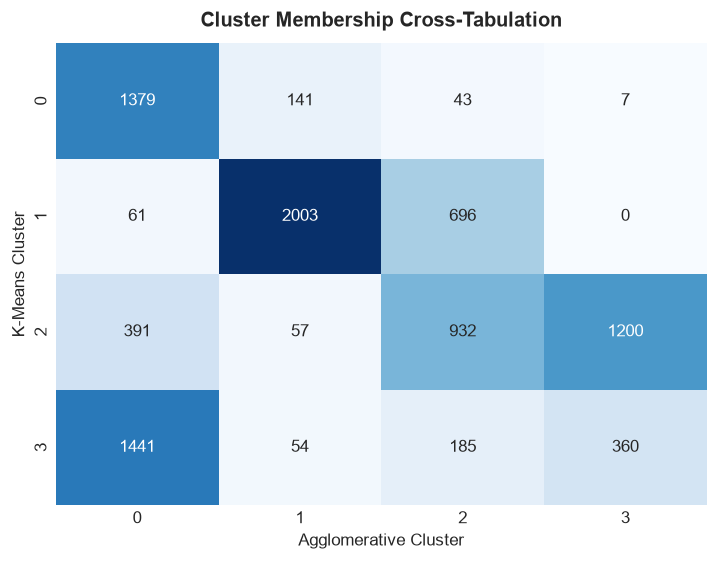

In [37]:
# Cross-Tabulation (Contingency Matrix) between K-Means and Agglomerative Clusters
contingency = pd.crosstab(
    df_clean['KMeans_Cluster'],
    df_clean['Agglomerative_Cluster'],
    rownames=['K-Means Cluster'],
    colnames=['Agglomerative Cluster']
)

plt.figure(figsize=(7, 5))
sns.heatmap(contingency, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Cluster Membership Cross-Tabulation', fontsize=12, fontweight='bold', pad=10)
plt.show()